# Step 3: Exploratory Data Analysis & Business KPIs

**E-Commerce 360° Business Intelligence Platform**

In-depth analysis of sales trends, category performance, and logistics elasticity.


### 1. Environment & Setup
Set up visualization styles and load curated fact tables.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 5)

PROCESSED_DIR = r'data/processed'
df_orders = pd.read_csv(f'{PROCESSED_DIR}/order_summary_bi.csv')
df_items = pd.read_csv(f'{PROCESSED_DIR}/fact_order_items.csv')
df_prod = pd.read_csv(f'{PROCESSED_DIR}/dim_products.csv')
print('Processed datasets loaded.')

Processed datasets loaded.


### 2. Monthly Revenue Trend & Seasonality
Aggregate delivered orders to evaluate growth trajectory and revenue peaks.

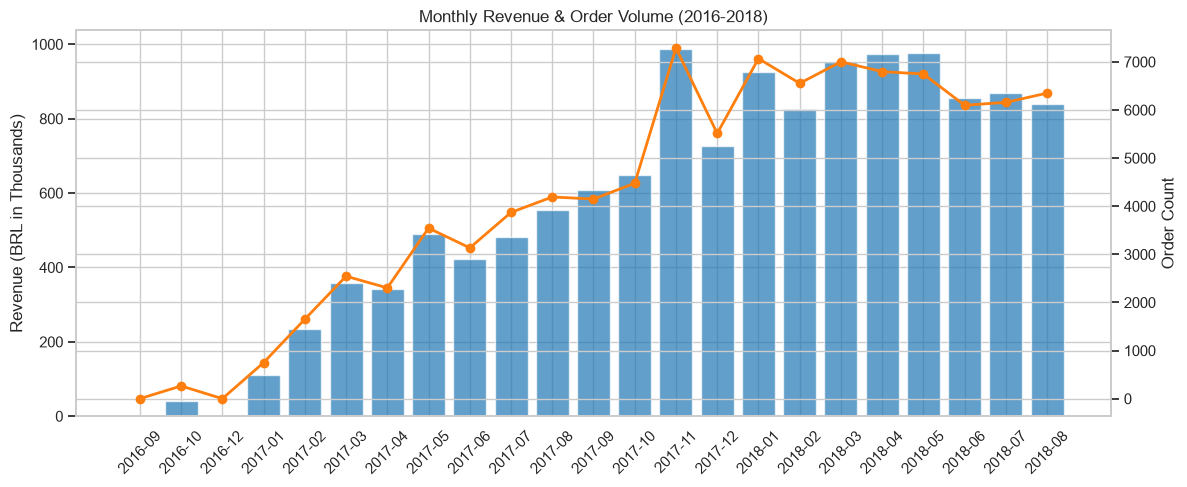

In [2]:
df_orders['purchase_date'] = pd.to_datetime(df_orders['purchase_date'])
delivered = df_orders[df_orders['order_status'] == 'delivered'].copy()
delivered['sales_month'] = delivered['purchase_date'].dt.to_period('M').astype(str)

m_revenue = delivered.groupby('sales_month')['total_item_revenue'].agg(['sum', 'count']).reset_index()
m_revenue.columns = ['Month', 'Revenue', 'Order Count']

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

ax1.bar(m_revenue['Month'], m_revenue['Revenue'] / 1e3, color='#1f77b4', alpha=0.7, label='Revenue (k BRL)')
ax2.plot(m_revenue['Month'], m_revenue['Order Count'], color='#ff7f0e', marker='o', linewidth=2, label='Orders')

ax1.tick_params(axis='x', rotation=45)
ax1.set_ylabel('Revenue (BRL in Thousands)')
ax2.set_ylabel('Order Count')
ax1.set_title('Monthly Revenue & Order Volume (2016-2018)')
plt.tight_layout()
plt.show()

### 3. Top 10 Product Categories by Realized Revenue
Join items with product dimension to identify primary revenue drivers.

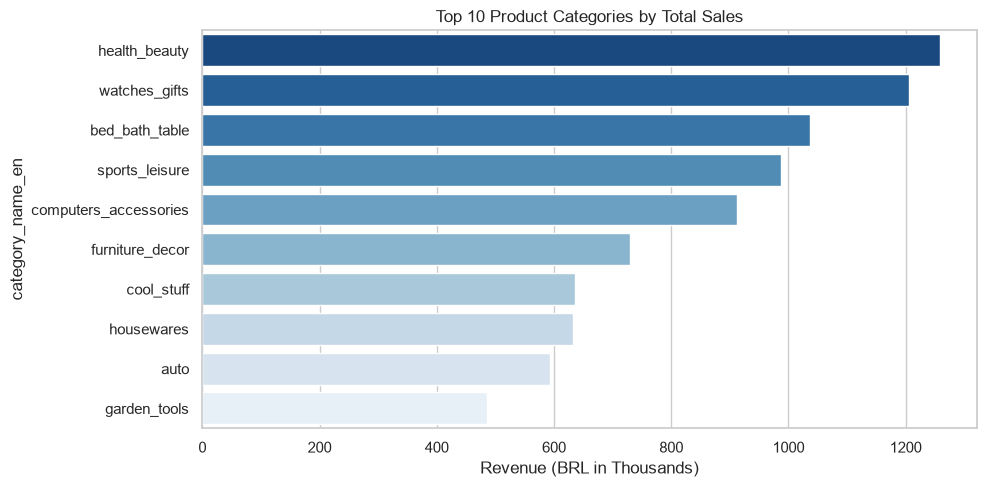

In [3]:
items_prod = df_items.merge(df_prod, on='product_id', how='left')
top_cats = items_prod.groupby('category_name_en')['price'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_cats.values / 1e3, y=top_cats.index, hue=top_cats.index, palette='Blues_r', legend=False)
plt.xlabel('Revenue (BRL in Thousands)')
plt.title('Top 10 Product Categories by Total Sales')
plt.tight_layout()
plt.show()

### 4. Delivery SLA vs. Customer Review Score
Evaluate how transit latency impacts customer satisfaction ratings.

C:\Users\91979\AppData\Local\Temp\ipykernel_11864\3297427953.py:19: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\91979\OneDrive\Desktop\Data Analyst\Projects\DA_Project_1\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


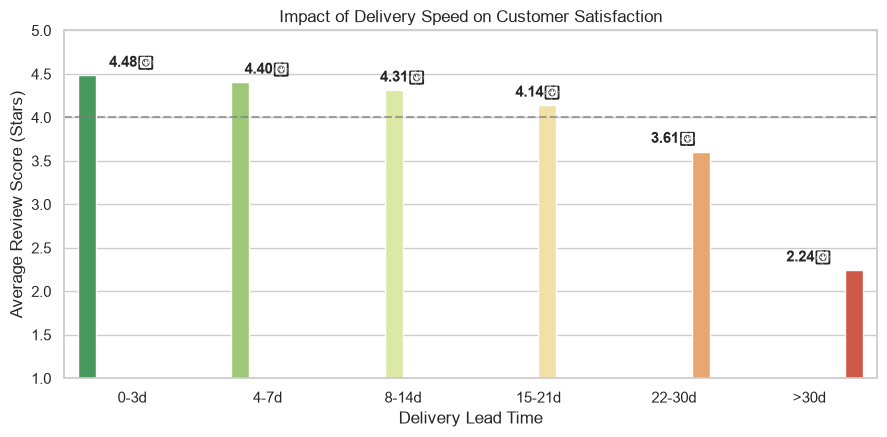

In [4]:
df_valid = df_orders.dropna(subset=['delivery_lead_time_days', 'avg_review_score']).copy()
df_valid['lead_time_bin'] = pd.cut(
    df_valid['delivery_lead_time_days'],
    bins=[-1, 3, 7, 14, 21, 30, 100],
    labels=['0-3d', '4-7d', '8-14d', '15-21d', '22-30d', '>30d']
)

csat_bin = df_valid.groupby('lead_time_bin', observed=False)['avg_review_score'].agg(['mean', 'count']).reset_index()

plt.figure(figsize=(9, 4.5))
sns.barplot(x='lead_time_bin', y='mean', data=csat_bin, hue='lead_time_bin', palette='RdYlGn_r', legend=False)
plt.axhline(4.0, color='grey', linestyle='--', alpha=0.7)
plt.ylim(1, 5)
plt.ylabel('Average Review Score (Stars)')
plt.xlabel('Delivery Lead Time')
plt.title('Impact of Delivery Speed on Customer Satisfaction')
for i, row in csat_bin.iterrows():
    plt.text(i, row['mean'] + 0.1, f"{row['mean']:.2f}★", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()